In [ ]:
import pandas as pd
import numpy as np
from scipy.stats import mannwhitneyu
from tqdm.auto import tqdm
import matplotlib.pyplot as plt

In [ ]:
import pandas as pd
import numpy as np

from google.colab import files

uploaded = files.upload()

print("\nUploaded files:")
for f in uploaded.keys():
    print(f)

Saving human_video_channels.csv to human_video_channels.csv
Saving ai_video_channels.csv to ai_video_channels.csv
Saving ai_features_v3.csv to ai_features_v3.csv
Saving human_features_v3.csv to human_features_v3.csv

Uploaded files:
human_video_channels.csv
ai_video_channels.csv
ai_features_v3.csv
human_features_v3.csv


In [ ]:
files_uploaded = list(uploaded.keys())

print(files_uploaded)

ai_features_file = "ai_features_v3.csv"
human_features_file = "human_features_v3.csv"

ai_channels_file = "ai_video_channels.csv"
human_channels_file = "human_video_channels.csv"

['human_video_channels.csv', 'ai_video_channels.csv', 'ai_features_v3.csv', 'human_features_v3.csv']


In [ ]:
# Read feature CSVs
ai_df = pd.read_csv(ai_features_file)
human_df = pd.read_csv(human_features_file)

# Read channel CSVs
ai_channels = pd.read_csv(ai_channels_file)
human_channels = pd.read_csv(human_channels_file)

# Keep only what we need from channel files
ai_channels = ai_channels[["video_id", "channel_name"]]
human_channels = human_channels[["video_id", "channel_name"]]

# Merge channel information into feature data
ai_df = ai_df.merge(
    ai_channels,
    on="video_id",
    how="left"
)

human_df = human_df.merge(
    human_channels,
    on="video_id",
    how="left"
)

# Explicitly set labels
ai_df["label"] = "ai"
human_df["label"] = "human"

# Combine
df = pd.concat(
    [ai_df, human_df],
    ignore_index=True
)

print("AI videos:", len(ai_df))
print("Human videos:", len(human_df))
print("Total:", len(df))

print("\nMissing channel names:")
print(df["channel_name"].isna().sum())

df.head()

AI videos: 200
Human videos: 200
Total: 400

Missing channel names:
6


,video_id,filename,label,duration_sec,has_audio,brightness_mean,brightness_var,saturation_mean,saturation_var,color_warmness_pct,...,frames_sampled,num_cuts,shot_count_per_sec,avg_shot_duration_sec,loudness_rms,loudness_lufs,tempo_bpm,sound_brightness,channel_name,error
0,-TiE69UDDhs,-TiE69UDDhs_Kids_Ghibli_Anime_AI_Video_Magical...,ai,96.014,True,102.633766,1210.402092,155.982372,668.063727,0.735020,...,60,82,0.854042,1.170902,0.060092,-20.477809,112.347147,1946.970463,AI Tales Festival,NaN
1,0LpQz4okNnE,0LpQz4okNnE_1_to_10_Counting_Song_for_Kids_Fun...,ai,101.734,True,174.810466,171.181175,92.749070,113.051827,0.495386,...,60,32,0.314546,3.179187,0.124136,-16.829880,117.453835,2748.755836,AI Wonder World!,NaN
2,0UCZf_aE4wI,0UCZf_aE4wI_Twinkle_Twinkle_Little_Star_Cute_B...,ai,240.074,True,161.678188,1139.088483,152.910190,1171.479197,0.359686,...,60,62,0.258254,3.872161,0.109404,-18.657019,92.285156,2817.564722,Baby Bubbles - Twinkle ⭐,NaN
3,0fh-9-BhQmk,0fh-9-BhQmk_Motu_Patlu_Animal_Hybrid_in_Real_L...,ai,70.054,True,179.102472,1624.722755,74.581959,2483.963816,0.623447,...,60,40,0.570988,1.751350,0.207790,-14.188106,129.199219,2261.019448,RealToon AI•,NaN
4,1E74XGdz4gY,1E74XGdz4gY_AI_3D_AI_Animated_Tamil_Story.mp4,ai,159.094,True,128.586654,184.598207,102.946657,287.547602,0.699770,...,60,156,0.980552,1.019833,0.090256,-17.562058,123.046875,2119.063423,GD cartoon style 04,NaN


In [ ]:
print("Unique AI channels:",
      df[df["label"] == "ai"]["channel_name"].nunique())

print("Unique Human channels:",
      df[df["label"] == "human"]["channel_name"].nunique())

Unique AI channels: 147
Unique Human channels: 17


In [ ]:
print("\nAI channel distribution:")
print(
    df[df["label"] == "ai"]["channel_name"]
    .value_counts()
    .head(15)
)

print("\nHuman channel distribution:")
print(
    df[df["label"] == "human"]["channel_name"]
    .value_counts()
    .head(15)
)


AI channel distribution:
channel_name
Children"s New Rhymes    24
Fatimas world             7
Joy Jingles               4
tiny toons tv             3
AI  Tales  Festival       3
AI Kids                   2
Kiddovi                   2
Kids Madani Channel       2
தமிழ் குழந்தைகள்          2
Kuttipattalam             2
Kids Anima Fun            2
Kid Songs TV              2
HappiHop                  2
Future Ai Kids            2
Singaboo                  2
Name: count, dtype: int64

Human channel distribution:
channel_name
Sesame Street                                    32
Baby Shark - Pinkfong Kids’ Songs & Stories      29
PAW Patrol Official & Friends                    25
Thomas & Friends                                 24
Little Baby Bum - Nursery Rhymes & Kids Songs    22
Cocomelon - Nursery Rhymes                       11
Numberblocks                                      8
BabyBus - Preschool Songs & Learning Cartoons     8
ChuChu TV Nursery Rhymes & Kids Songs             8
GoNoo

In [ ]:
print(df.columns.tolist())

['video_id', 'filename', 'label', 'duration_sec', 'has_audio', 'brightness_mean', 'brightness_var', 'saturation_mean', 'saturation_var', 'color_warmness_pct', 'visual_complexity', 'frames_sampled', 'num_cuts', 'shot_count_per_sec', 'avg_shot_duration_sec', 'loudness_rms', 'loudness_lufs', 'tempo_bpm', 'sound_brightness', 'channel_name', 'error']


In [ ]:
GROUP_COL = "label"
CHANNEL_COL = "channel_name"

In [ ]:
print(df[GROUP_COL].value_counts())
AI_LABEL = "ai"
HUMAN_LABEL = "human"

label
ai       200
human    200
Name: count, dtype: int64


In [ ]:
# Check missing channel rows
print("Missing channel rows:")
print(df[df[CHANNEL_COL].isna()][
    ["video_id", "filename", "label"]
].to_string(index=False))

print("\nMissing by group:")
print(
    df[df[CHANNEL_COL].isna()]["label"].value_counts()
)

Missing channel rows:
Empty DataFrame
Columns: [video_id, filename, label]
Index: []

Missing by group:
Series([], Name: count, dtype: int64)


In [ ]:
print("Total rows:", len(df))
print("Unique video IDs:", df["video_id"].nunique())

duplicates = df[df["video_id"].duplicated(keep=False)]

print("\nDuplicate video IDs:", duplicates["video_id"].nunique())

if len(duplicates) > 0:
    print(duplicates[["video_id", "label", "channel_name"]]
          .sort_values("video_id")
          .to_string(index=False))

Total rows: 394
Unique video IDs: 394

Duplicate video IDs: 0


In [ ]:
ai_df = df[df[GROUP_COL] == AI_LABEL].copy()
human_df = df[df[GROUP_COL] == HUMAN_LABEL].copy()

print("AI videos:", len(ai_df))
print("Human videos:", len(human_df))

print("\nAI channels:", ai_df[CHANNEL_COL].nunique())
print("Human channels:", human_df[CHANNEL_COL].nunique())

print("\nHuman videos per channel:")
print(human_df[CHANNEL_COL].value_counts())

print("\nAI videos per channel:")
print(ai_df[CHANNEL_COL].value_counts().head(20))

AI videos: 194
Human videos: 200

AI channels: 147
Human channels: 17

Human videos per channel:
channel_name
Sesame Street                                    32
Baby Shark - Pinkfong Kids’ Songs & Stories      29
PAW Patrol Official & Friends                    25
Thomas & Friends                                 24
Little Baby Bum - Nursery Rhymes & Kids Songs    22
Cocomelon - Nursery Rhymes                       11
Numberblocks                                      8
BabyBus - Preschool Songs & Learning Cartoons     8
ChuChu TV Nursery Rhymes & Kids Songs             8
GoNoodle | Get Moving                             7
Super Simple Songs - Kids Songs                   7
Hey Duggee Official                               6
Bob the Builder                                   4
Peppa Pig - Official Channel                      3
Dr. Panda TotoTime – Official Channel             3
Peekaboo Kidz                                     2
Masha and The Bear                                1
Name: 

In [ ]:
FEATURES = [
    "visual_complexity",
    "saturation_var",
    "loudness_rms",
    "loudness_lufs",
    "brightness_var",
    "sound_brightness",
    "avg_shot_duration_sec",
    "brightness_mean",
    "num_cuts",
    "shot_count_per_sec",
    "saturation_mean",
    "duration_sec",
    "color_warmness_pct",
    "tempo_bpm"
]

In [ ]:
# Make sure feature columns are numeric
for feature in FEATURES:
    df[feature] = pd.to_numeric(df[feature], errors="coerce")

# Remove rows with missing group/channel
df = df.dropna(subset=[GROUP_COL, CHANNEL_COL])

print("Final dataset shape:", df.shape)

Final dataset shape: (394, 21)


In [ ]:
def cohens_d(ai_values, human_values):
    ai_values = np.asarray(ai_values, dtype=float)
    human_values = np.asarray(human_values, dtype=float)

    n1 = len(ai_values)
    n2 = len(human_values)

    mean1 = np.mean(ai_values)
    mean2 = np.mean(human_values)

    sd1 = np.std(ai_values, ddof=1)
    sd2 = np.std(human_values, ddof=1)

    pooled_sd = np.sqrt(
        ((n1 - 1) * sd1**2 + (n2 - 1) * sd2**2)
        / (n1 + n2 - 2)
    )

    if pooled_sd == 0:
        return np.nan

    return (mean1 - mean2) / pooled_sd

In [ ]:
N_ITERATIONS = 5000
RANDOM_SEED = 42

rng = np.random.default_rng(RANDOM_SEED)

human_channels = human_df[CHANNEL_COL].dropna().unique()
ai_channels = ai_df[CHANNEL_COL].dropna().unique()

n_human_channels = len(human_channels)

print("Human channels:", n_human_channels)
print("AI channels:", len(ai_channels))

if len(ai_channels) < n_human_channels:
    raise ValueError("Not enough AI channels for balanced resampling.")

# Store results
resampling_results = {
    feature: [] for feature in FEATURES
}

for iteration in tqdm(
    range(N_ITERATIONS),
    desc="Balanced resampling"
):

    # --------------------------------------------------
    # 1. Select exactly 17 AI channels
    # --------------------------------------------------
    selected_ai_channels = rng.choice(
        ai_channels,
        size=n_human_channels,
        replace=False
    )

    # --------------------------------------------------
    # 2. Select ONE random video from each AI channel
    # --------------------------------------------------
    selected_ai_videos = []

    for channel in selected_ai_channels:

        channel_videos = ai_df[
            ai_df[CHANNEL_COL] == channel
        ]

        selected_video = channel_videos.sample(
            n=1,
            random_state=int(rng.integers(0, 1_000_000_000))
        )

        selected_ai_videos.append(selected_video)

    balanced_ai = pd.concat(selected_ai_videos)

    # --------------------------------------------------
    # 3. Select ONE random video from EACH human channel
    # --------------------------------------------------
    selected_human_videos = []

    for channel in human_channels:

        channel_videos = human_df[
            human_df[CHANNEL_COL] == channel
        ]

        selected_video = channel_videos.sample(
            n=1,
            random_state=int(rng.integers(0, 1_000_000_000))
        )

        selected_human_videos.append(selected_video)

    balanced_human = pd.concat(selected_human_videos)

    # --------------------------------------------------
    # 4. Calculate Cohen's d for every feature
    # --------------------------------------------------
    for feature in FEATURES:

        ai_values = balanced_ai[feature].dropna().values
        human_values = balanced_human[feature].dropna().values

        if len(ai_values) < 2 or len(human_values) < 2:
            d = np.nan
        else:
            d = cohens_d(ai_values, human_values)

        resampling_results[feature].append(d)

Human channels: 17
AI channels: 147


Balanced resampling:   0%|          | 0/5000 [00:00<?, ?it/s]

In [ ]:
results_df = pd.DataFrame(resampling_results)

print(results_df.shape)
results_df.head()

(5000, 14)


,visual_complexity,saturation_var,loudness_rms,loudness_lufs,brightness_var,sound_brightness,avg_shot_duration_sec,brightness_mean,num_cuts,shot_count_per_sec,saturation_mean,duration_sec,color_warmness_pct,tempo_bpm
0,1.335913,-0.738393,0.334417,0.203219,-0.184795,-0.253246,0.474318,-0.409186,-0.816086,-0.406875,-0.051532,-0.866242,0.662074,-0.703932
1,1.032809,-0.716783,0.645117,0.427686,-0.233576,-0.139674,0.411756,-0.972531,-0.860308,-0.358161,0.050755,-0.799263,0.400360,0.086017
2,1.208356,-0.512970,0.140883,-0.039425,-0.279002,-0.226294,0.362063,-0.570013,-0.631694,0.021914,-0.466754,-0.724057,0.611166,-0.760733
3,1.006643,-0.727269,-0.193349,-0.426600,-0.384994,-0.240504,0.491027,-0.802781,-0.552524,0.078426,0.162271,-0.818617,0.518405,-1.043166
4,1.073556,-0.706235,0.495010,0.167821,-0.107726,0.083384,0.476156,-0.810300,-0.635285,-0.402326,0.088207,-0.713669,-0.068920,0.241431


In [ ]:
summary = []

for feature in FEATURES:

    values = results_df[feature].dropna().values

    median_d = np.median(values)

    lower = np.percentile(values, 2.5)
    upper = np.percentile(values, 97.5)

    # How often was AI > Human?
    direction_consistency = np.mean(values > 0) * 100

    summary.append({
        "feature": feature,
        "median_d": median_d,
        "CI_2.5%": lower,
        "CI_97.5%": upper,
        "AI_higher_%": direction_consistency
    })

summary_df = pd.DataFrame(summary)

summary_df = summary_df.sort_values(
    "median_d",
    key=lambda x: abs(x),
    ascending=False
)

summary_df

,feature,median_d,CI_2.5%,CI_97.5%,AI_higher_%
0,visual_complexity,1.207896,0.770959,1.679569,100.00
7,brightness_mean,-0.831622,-1.497244,-0.285198,0.12
1,saturation_var,-0.706635,-1.367434,-0.110897,0.80
11,duration_sec,-0.676881,-1.001732,-0.369665,0.06
8,num_cuts,-0.573870,-1.002186,-0.061074,1.48
2,loudness_rms,0.481854,-0.094822,1.049292,94.90
6,avg_shot_duration_sec,0.330727,-0.420632,0.705544,82.36
3,loudness_lufs,0.328925,-0.205251,0.902094,87.86
13,tempo_bpm,-0.310886,-0.939791,0.336455,16.74
4,brightness_var,-0.285632,-0.924266,0.294162,17.48


In [ ]:
original_d = {
    "visual_complexity": 1.09,
    "saturation_var": -0.73,
    "loudness_rms": 0.70,
    "loudness_lufs": 0.56,
    "brightness_var": -0.36,
    "sound_brightness": -0.33,
    "avg_shot_duration_sec": 0.29,
    "brightness_mean": -0.28,
    "num_cuts": -0.27,
    "shot_count_per_sec": -0.20,
    "saturation_mean": 0.21,
    "duration_sec": -0.14,
    "color_warmness_pct": -0.13,
    "tempo_bpm": -0.05
}

summary_df["original_d"] = summary_df["feature"].map(original_d)

summary_df["direction_matches_original"] = (
    np.sign(summary_df["median_d"]) ==
    np.sign(summary_df["original_d"])
)

summary_df

,feature,median_d,CI_2.5%,CI_97.5%,AI_higher_%,original_d,direction_matches_original
0,visual_complexity,1.207896,0.770959,1.679569,100.00,1.09,True
7,brightness_mean,-0.831622,-1.497244,-0.285198,0.12,-0.28,True
1,saturation_var,-0.706635,-1.367434,-0.110897,0.80,-0.73,True
11,duration_sec,-0.676881,-1.001732,-0.369665,0.06,-0.14,True
8,num_cuts,-0.573870,-1.002186,-0.061074,1.48,-0.27,True
2,loudness_rms,0.481854,-0.094822,1.049292,94.90,0.70,True
6,avg_shot_duration_sec,0.330727,-0.420632,0.705544,82.36,0.29,True
3,loudness_lufs,0.328925,-0.205251,0.902094,87.86,0.56,True
13,tempo_bpm,-0.310886,-0.939791,0.336455,16.74,-0.05,True
4,brightness_var,-0.285632,-0.924266,0.294162,17.48,-0.36,True


In [ ]:
final_table = summary_df[
    [
        "feature",
        "original_d",
        "median_d",
        "CI_2.5%",
        "CI_97.5%",
        "AI_higher_%",
        "direction_matches_original"
    ]
].copy()

final_table

,feature,original_d,median_d,CI_2.5%,CI_97.5%,AI_higher_%,direction_matches_original
0,visual_complexity,1.09,1.207896,0.770959,1.679569,100.00,True
7,brightness_mean,-0.28,-0.831622,-1.497244,-0.285198,0.12,True
1,saturation_var,-0.73,-0.706635,-1.367434,-0.110897,0.80,True
11,duration_sec,-0.14,-0.676881,-1.001732,-0.369665,0.06,True
8,num_cuts,-0.27,-0.573870,-1.002186,-0.061074,1.48,True
2,loudness_rms,0.70,0.481854,-0.094822,1.049292,94.90,True
6,avg_shot_duration_sec,0.29,0.330727,-0.420632,0.705544,82.36,True
3,loudness_lufs,0.56,0.328925,-0.205251,0.902094,87.86,True
13,tempo_bpm,-0.05,-0.310886,-0.939791,0.336455,16.74,True
4,brightness_var,-0.36,-0.285632,-0.924266,0.294162,17.48,True


In [ ]:
results_df.to_csv(
    "balanced_resampling_all_5000_iterations.csv",
    index=False
)

final_table.to_csv(
    "balanced_resampling_summary.csv",
    index=False
)

print("Saved:")
print("- balanced_resampling_all_5000_iterations.csv")
print("- balanced_resampling_summary.csv")


from google.colab import files

files.download("balanced_resampling_summary.csv")

Saved:
- balanced_resampling_all_5000_iterations.csv
- balanced_resampling_summary.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

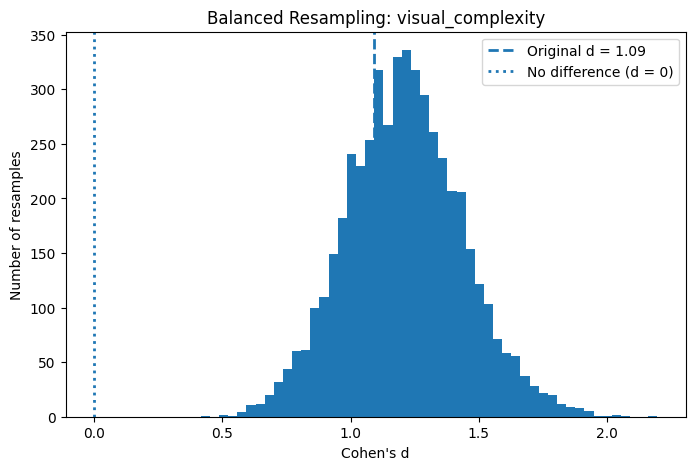

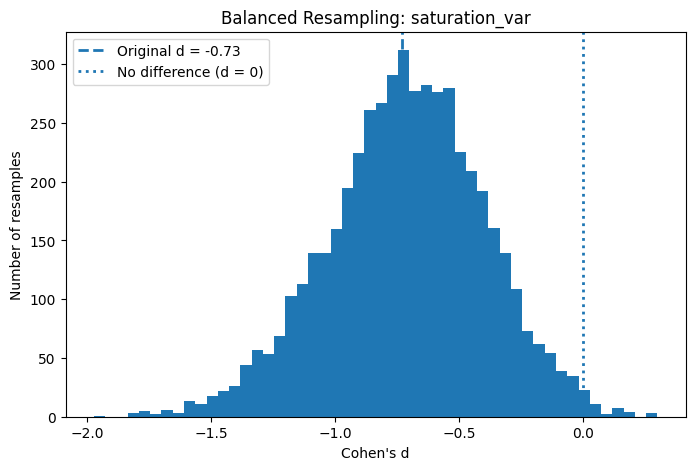

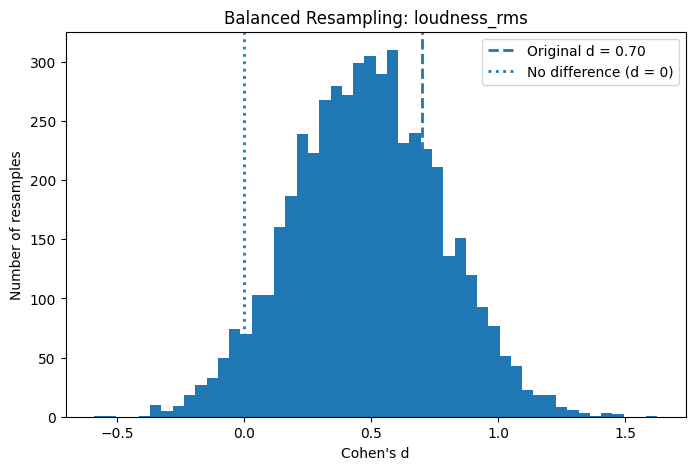

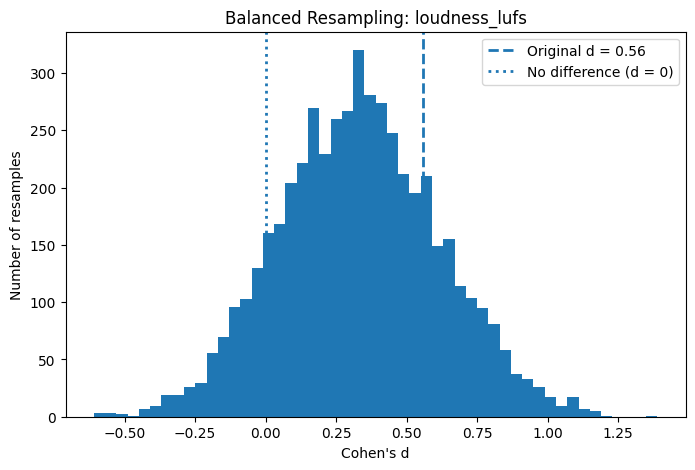

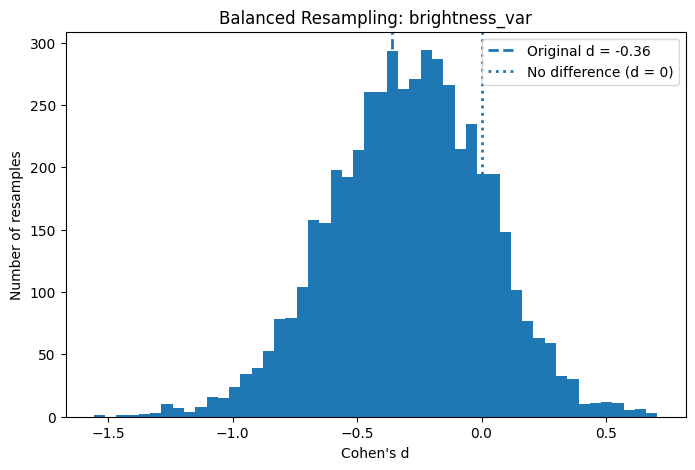

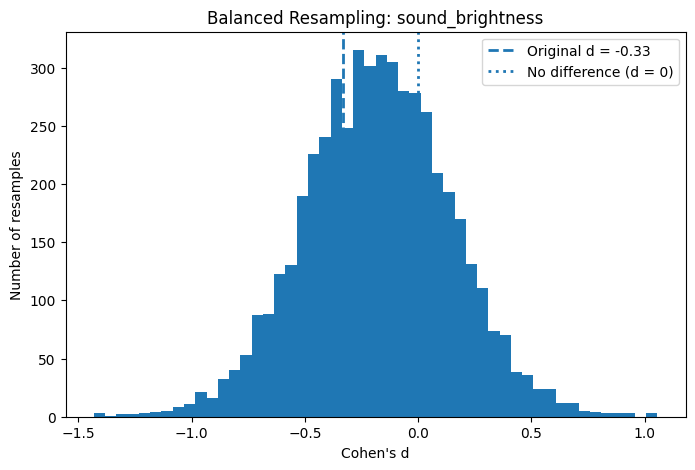

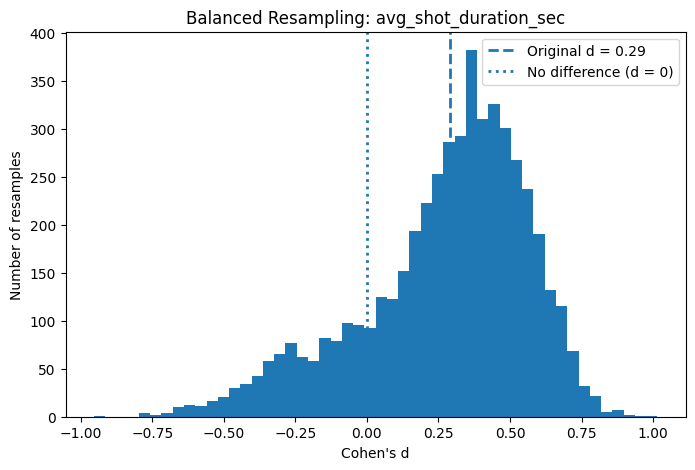

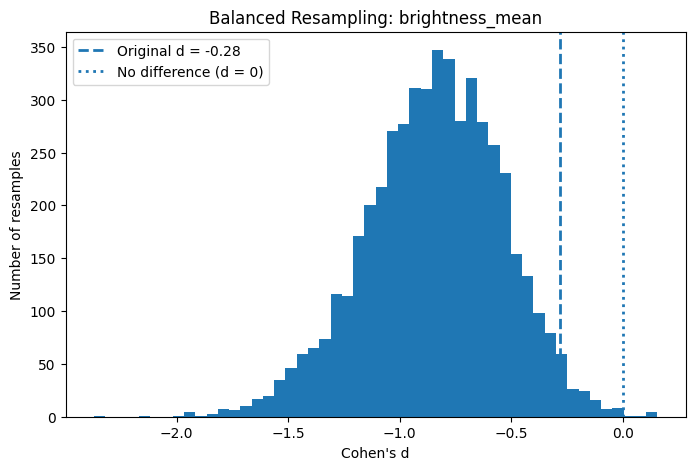

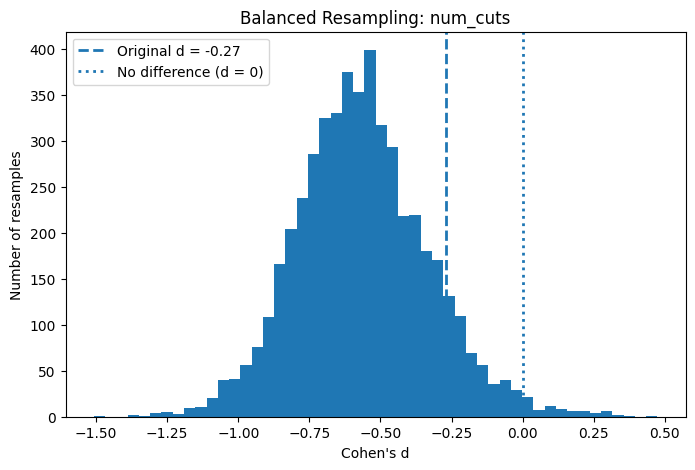

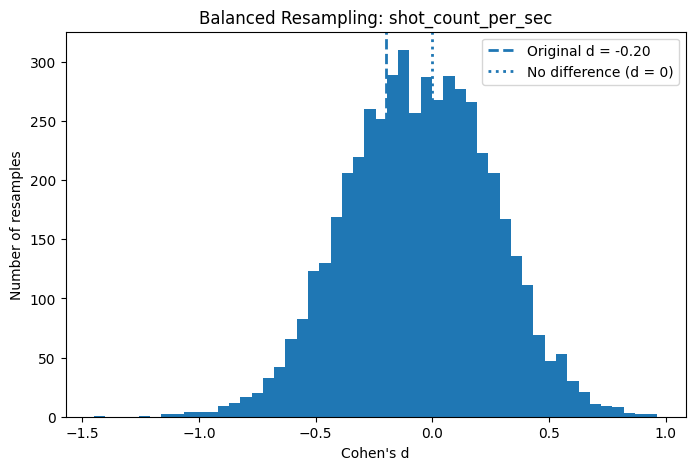

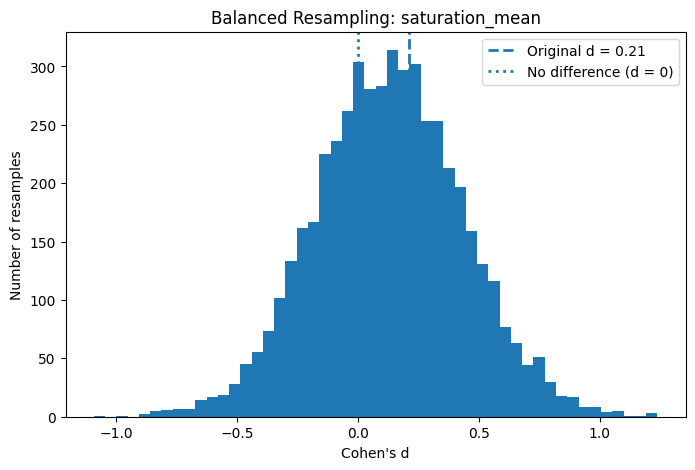

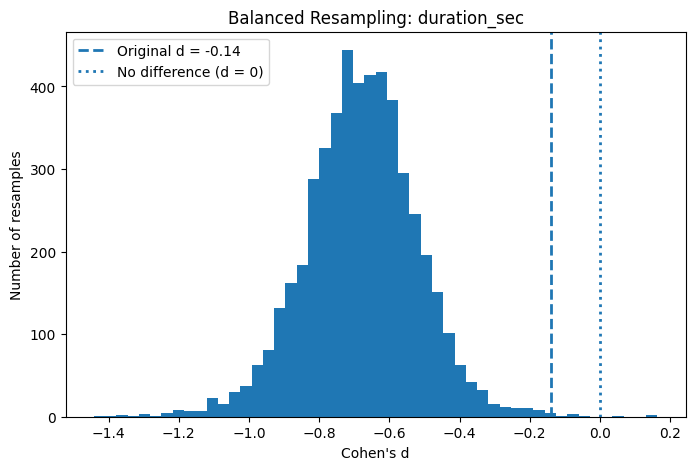

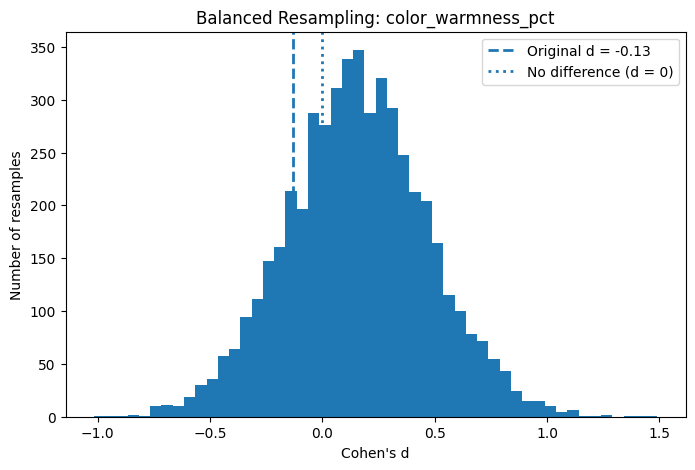

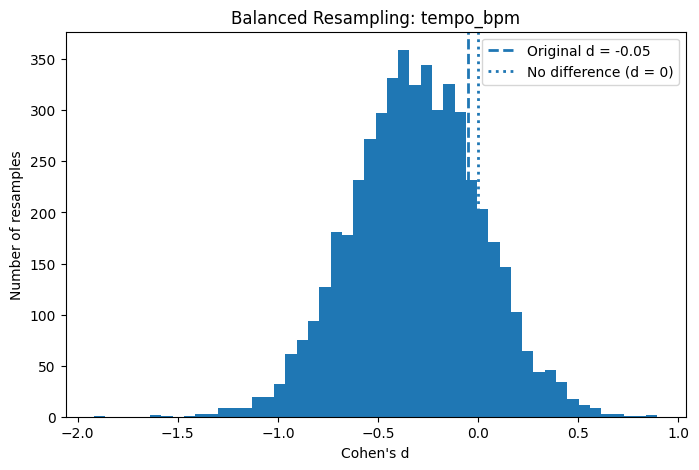

In [ ]:
for feature in FEATURES:

    values = results_df[feature].dropna()

    plt.figure(figsize=(8, 5))

    plt.hist(values, bins=50)

    # Original Cohen's d
    if feature in original_d:
        plt.axvline(
            original_d[feature],
            linestyle="--",
            linewidth=2,
            label=f"Original d = {original_d[feature]:.2f}"
        )

    # Zero = no directional difference
    plt.axvline(
        0,
        linestyle=":",
        linewidth=2,
        label="No difference (d = 0)"
    )

    plt.xlabel("Cohen's d")
    plt.ylabel("Number of resamples")
    plt.title(f"Balanced Resampling: {feature}")
    plt.legend()

    plt.show()